# Experiment 4: Hill climbing

Steepest-ascent hill climbing on a 1-D landscape and on eight queens, and the
effect of random restarts compared with the prediction 1 - (1 - p)^k.

In [1]:
import json, random
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10})
TRIALS = 200

## The landscape, and where a 1-D hill climber gets stuck

7 local maxima; global at x = 7.65, f = 1.550
1-D climbs from 25 evenly spaced starts reaching the global maximum: 24%


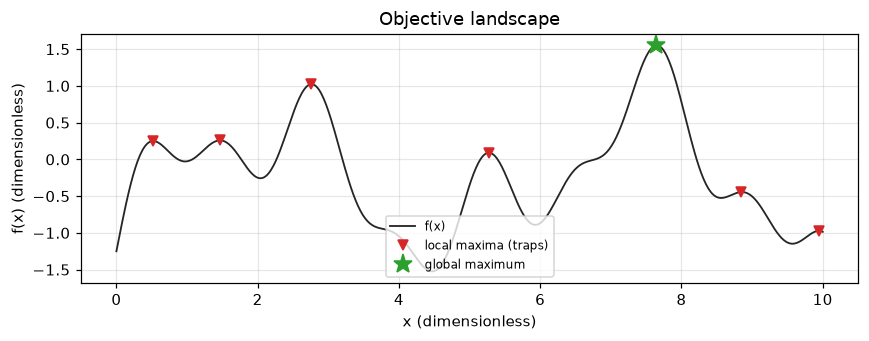

In [2]:
xs = np.linspace(0, 10, 600)
f = lambda x: np.sin(x) + 0.6*np.sin(2.7*x) + 0.35*np.sin(5.1*x) - 0.05*(x - 5)**2
fx = f(xs)
peaks = argrelextrema(fx, np.greater)[0]
g = peaks[np.argmax(fx[peaks])]

def climb_1d(x, step=xs[1] - xs[0]):
    """Move to the better neighbour until neither neighbour is better."""
    while True:
        best = max((x - step, x, x + step), key=f)
        if best == x:
            return x
        x = best

ends = [climb_1d(x0) for x0 in np.linspace(0.2, 9.8, 25)]
reach_global = np.mean([abs(e - xs[g]) < 0.05 for e in ends])
print(f'{len(peaks)} local maxima; global at x = {xs[g]:.2f}, f = {fx[g]:.3f}')
print(f'1-D climbs from 25 evenly spaced starts reaching the global maximum: {100*reach_global:.0f}%')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(xs, fx, lw=1.2, color='0.15', label='f(x)')
loc = [p for p in peaks if p != g]
ax.plot(xs[loc], fx[loc], 'v', color='tab:red', ms=7, label='local maxima (traps)')
ax.plot(xs[g], fx[g], '*', color='tab:green', ms=13, label='global maximum')
ax.set_xlabel('x (dimensionless)'); ax.set_ylabel('f(x) (dimensionless)')
ax.set_title('Objective landscape'); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower center')
fig.tight_layout(); fig.savefig('figs/fig4_1_landscape.png')

## Hill climbing on eight queens (minimise attacking pairs)

In [3]:
def conflicts(board):
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def hill_climb(n=8, seed=0, sideways=0):
    """Steepest descent on conflicts. `sideways` = number of equal-cost moves allowed."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]
    side_left = sideways
    while True:
        current = conflicts(board)
        if current == 0:
            return True
        best, moves = current, []
        for c in range(n):
            old = board[c]
            for row in range(n):
                if row == old:
                    continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, moves = v, [(c, row)]
                elif v == best:
                    moves.append((c, row))
            board[c] = old
        if best < current:
            c, row = moves[0]
        elif best == current and moves and side_left > 0:
            c, row = r.choice(moves); side_left -= 1      # plateau: take a sideways move
        else:
            return False                                  # local minimum
        board[c] = row

def hill_climb_restarts(n=8, restarts=10, seed=0):
    return any(hill_climb(n, seed=seed*1000 + k) for k in range(restarts))

succ = sum(hill_climb(8, seed=s) for s in range(TRIALS))
p = succ / TRIALS
print(f'plain hill climbing: {succ}/{TRIALS} = {100*p:.1f}%')

succ_b = sum(hill_climb(8, seed=10_000 + s) for s in range(TRIALS))
print(f'repeat with different seeds: {succ_b}/{TRIALS} = {100*succ_b/TRIALS:.1f}%')

succ_side = sum(hill_climb(8, seed=s, sideways=100) for s in range(TRIALS))
print(f'with up to 100 sideways moves: {succ_side}/{TRIALS} = {100*succ_side/TRIALS:.1f}%')

plain hill climbing: 25/200 = 12.5%


repeat with different seeds: 32/200 = 16.0%


with up to 100 sideways moves: 189/200 = 94.5%


## Random restarts

k =  1: measured  14.5%  predicted  12.5%  (200 trials)
k =  2: measured  25.5%  predicted  23.4%  (200 trials)


k =  5: measured  56.0%  predicted  48.7%  (200 trials)


k = 10: measured  78.0%  predicted  73.7%  (200 trials)


k = 20: measured  97.5%  predicted  93.1%  (200 trials)
restarts needed for 99% success at this p: 35


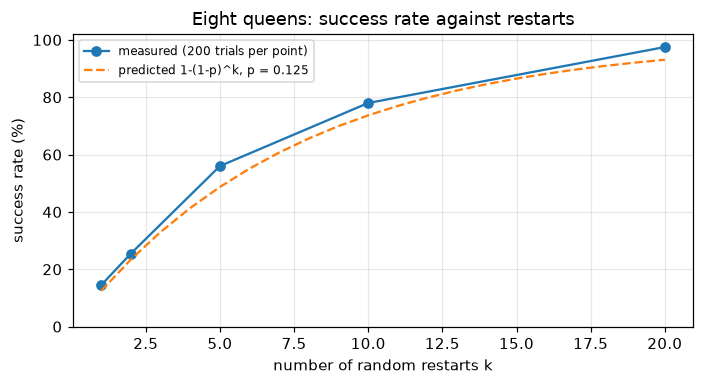

In [4]:
ks = [1, 2, 5, 10, 20]
rows = []
for k in ks:
    ok = sum(hill_climb_restarts(8, k, seed=1000 + s) for s in range(TRIALS)) / TRIALS
    pred = 1 - (1 - p)**k
    rows.append(dict(k=k, trials=TRIALS, measured=100*ok, predicted=100*pred))
    print(f'k = {k:>2}: measured {100*ok:5.1f}%  predicted {100*pred:5.1f}%  ({TRIALS} trials)')

k99 = int(np.ceil(np.log(0.01) / np.log(1 - p)))
print('restarts needed for 99% success at this p:', k99)

kk = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot([r['k'] for r in rows], [r['measured'] for r in rows], 'o-', label=f'measured ({TRIALS} trials per point)')
ax.plot(kk, 100*(1 - (1 - p)**kk), '--', label=f'predicted 1-(1-p)^k, p = {p:.3f}')
ax.set_xlabel('number of random restarts k'); ax.set_ylabel('success rate (%)')
ax.set_ylim(0, 102); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title('Eight queens: success rate against restarts')
fig.tight_layout(); fig.savefig('figs/fig4_2_restarts.png')

In [5]:
with open('obs.json', 'w') as fh:
    json.dump(dict(trials=TRIALS, successes=succ, p=p, successes_repeat=succ_b,
                   sideways_successes=succ_side, restarts=rows, k99=k99,
                   n_local_maxima=int(len(peaks)), x_global=float(xs[g]),
                   oned_reach_global=float(reach_global)), fh, indent=1)